# Unveiling the Android App Market
**Google Play Store Analysis**

**Oasis Infobyte Data Analytics Internship — Level 2, Task 4**

---

## 1. Business Problem

The Android app market is highly competitive. Developers need to understand market trends — which categories are saturated, how pricing impacts downloads, and what users care about in reviews — to successfully launch and monetize new applications.

## 2. Objective

Perform a comprehensive analysis of the Google Play Store ecosystem. This includes cleaning real-world data, analyzing app categories, ratings, sizes, and pricing, and conducting sentiment analysis on user reviews to provide data-driven recommendations for app developers.

## 3. Dataset Overview

We use two datasets from Kaggle:
1. **`googleplaystore.csv`**: Contains data on 10,000+ apps (Category, Rating, Size, Installs, Type, Price, etc.).
2. **`googleplaystore_user_reviews.csv`**: Contains user reviews and pre-calculated sentiment scores (Polarity/Subjectivity), which we will analyze using TextBlob/VADER logic.

## 4. Data Loading & Inspection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from textblob import TextBlob
import os
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

os.makedirs('outputs', exist_ok=True)

# Load data
apps_df = pd.read_csv('data/googleplaystore.csv')
reviews_df = pd.read_csv('data/googleplaystore_user_reviews.csv')

print(f"Apps Dataset: {apps_df.shape[0]} rows, {apps_df.shape[1]} columns")
print(f"Reviews Dataset: {reviews_df.shape[0]} rows, {reviews_df.shape[1]} columns")

Apps Dataset: 10841 rows, 13 columns
Reviews Dataset: 64295 rows, 5 columns


## 5. Data Cleaning (Apps Dataset)

In [2]:
# Drop duplicates
apps_df.drop_duplicates(subset=['App'], inplace=True)

# 1. Clean 'Installs' (e.g., '10,000+' -> 10000)
apps_df['Installs'] = apps_df['Installs'].str.replace('+', '', regex=False)
apps_df['Installs'] = apps_df['Installs'].str.replace(',', '', regex=False)
apps_df['Installs'] = pd.to_numeric(apps_df['Installs'], errors='coerce')

# 2. Clean 'Price' (e.g., '$4.99' -> 4.99)
apps_df['Price'] = apps_df['Price'].str.replace('$', '', regex=False)
apps_df['Price'] = pd.to_numeric(apps_df['Price'], errors='coerce')

# 3. Clean 'Size' (convert M/k to standard numeric megabytes)
def clean_size(size_str):
    if pd.isna(size_str) or size_str == 'Varies with device':
        return np.nan
    if 'M' in size_str:
        return float(size_str.replace('M', ''))
    elif 'k' in size_str:
        return float(size_str.replace('k', '')) / 1024  # convert KB to MB
    return np.nan

apps_df['Size_MB'] = apps_df['Size'].apply(clean_size)

# Drop rows with major missing values or corrupted rows (like the famous row 10472 shift error)
apps_df = apps_df.dropna(subset=['Installs', 'Rating', 'Type'])

print("Cleaned Apps Data Types:")
print(apps_df[['Installs', 'Price', 'Size_MB', 'Rating']].dtypes)
print(f"\nCleaned Apps Shape: {apps_df.shape}")

Cleaned Apps Data Types:
Installs    float64
Price       float64
Size_MB     float64
Rating      float64
dtype: object

Cleaned Apps Shape: (8196, 14)


## 6. Category Analysis

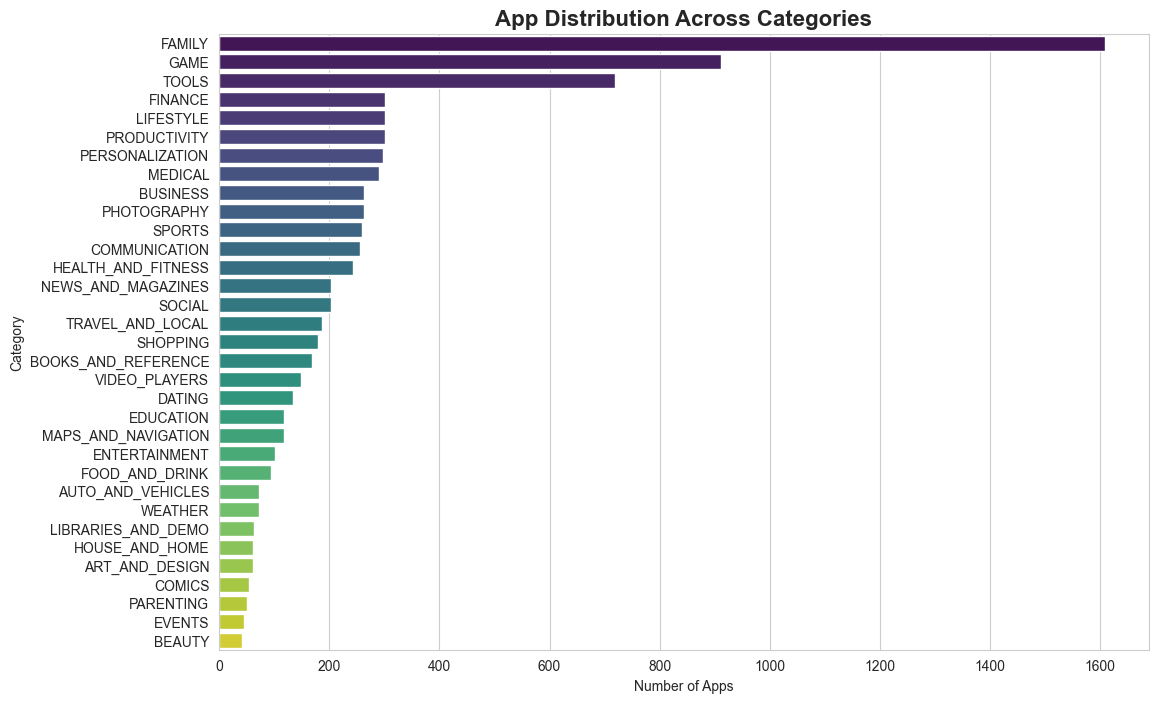

Top 5 Most Saturated Categories:
Category
FAMILY       1608
GAME          912
TOOLS         718
FINANCE       302
LIFESTYLE     301
Name: count, dtype: int64


In [3]:
# App distribution by category
cat_counts = apps_df['Category'].value_counts()

plt.figure(figsize=(12, 8))
sns.barplot(x=cat_counts.values, y=cat_counts.index, palette='viridis')
plt.title('App Distribution Across Categories', fontsize=16, fontweight='bold')
plt.xlabel('Number of Apps')
plt.ylabel('Category')
plt.savefig('outputs/category_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("Top 5 Most Saturated Categories:")
print(cat_counts.head(5))

**Observation:** `FAMILY`, `GAME`, and `TOOLS` are the most saturated categories. Entering these markets requires significant differentiation.

## 7. Ratings Analysis

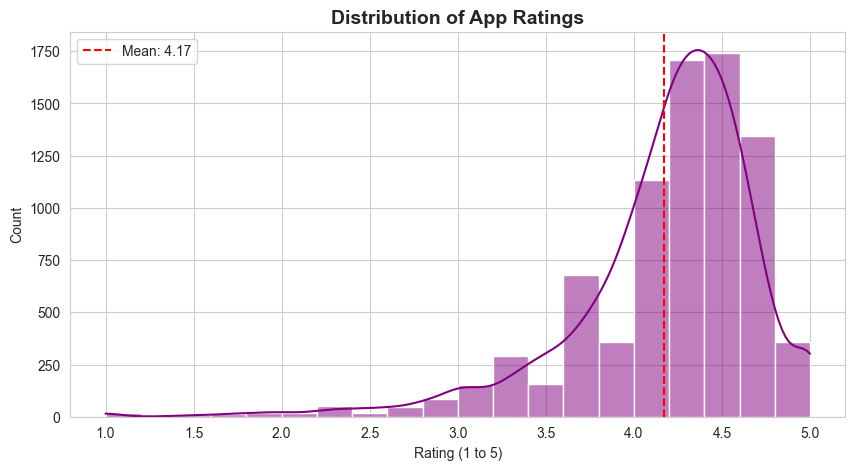

In [4]:
plt.figure(figsize=(10, 5))
sns.histplot(apps_df['Rating'], bins=20, kde=True, color='purple')
plt.title('Distribution of App Ratings', fontsize=14, fontweight='bold')
plt.xlabel('Rating (1 to 5)')
plt.axvline(apps_df['Rating'].mean(), color='r', linestyle='--', label=f'Mean: {apps_df["Rating"].mean():.2f}')
plt.legend()
plt.savefig('outputs/rating_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:** Ratings are heavily left-skewed. Most apps are rated between 4.0 and 4.5. A rating below 4.0 is considered poor in this ecosystem.

## 8. Size and Installs Analysis

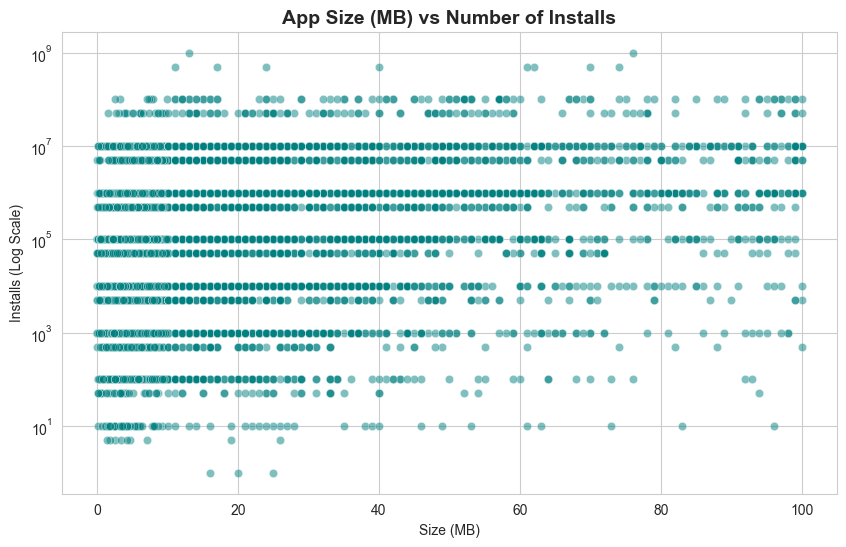

In [5]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Size_MB', y='Installs', data=apps_df, alpha=0.5, color='teal')
plt.yscale('log')  # Log scale for installs due to extreme range
plt.title('App Size (MB) vs Number of Installs', fontsize=14, fontweight='bold')
plt.xlabel('Size (MB)')
plt.ylabel('Installs (Log Scale)')
plt.savefig('outputs/size_vs_installs.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:** There isn't a strict linear correlation, but very large apps (>80MB) rarely hit the absolute maximum install tiers unless they are highly popular games. Smaller apps have a wider variance of success.

## 9. Pricing Analysis

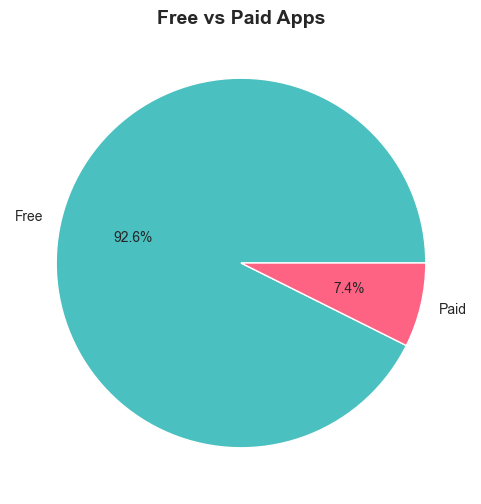

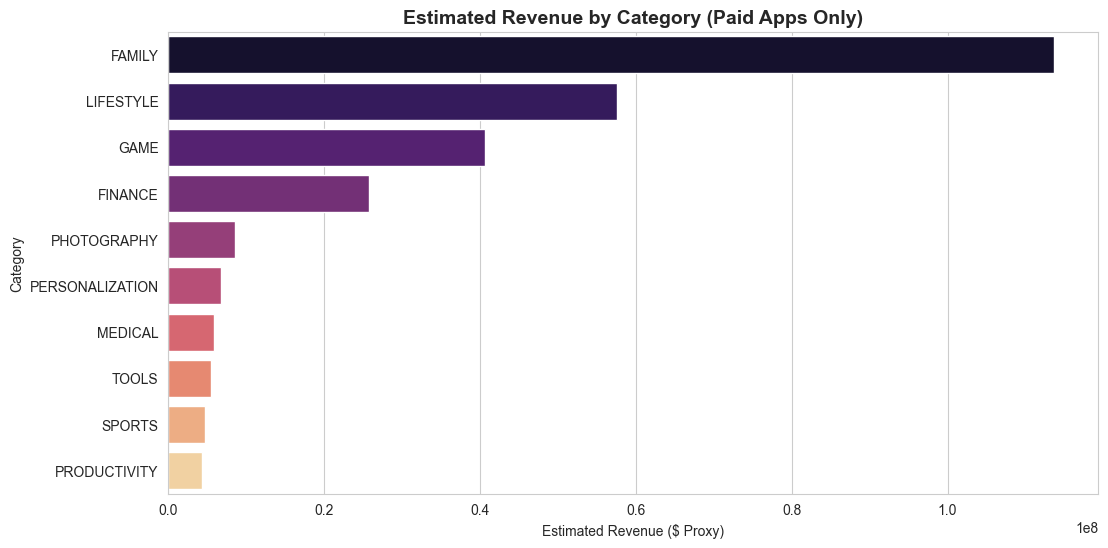

In [6]:
# Free vs Paid Distribution
type_counts = apps_df['Type'].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%', colors=['#4BC0C0', '#FF6384'])
plt.title('Free vs Paid Apps', fontsize=14, fontweight='bold')
plt.savefig('outputs/free_vs_paid.png', dpi=150, bbox_inches='tight')
plt.show()

# Revenue Estimate (Proxy: Price * Installs)
# *NOTE: This is a highly estimated proxy since 'Installs' is a banded metric (e.g., 10k+) 
# and doesn't account for refunds, region pricing, or in-app purchases.*
apps_df['Estimated_Revenue'] = apps_df['Price'] * apps_df['Installs']

paid_apps = apps_df[apps_df['Type'] == 'Paid']
category_revenue = paid_apps.groupby('Category')['Estimated_Revenue'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=category_revenue.values, y=category_revenue.index, palette='magma')
plt.title('Estimated Revenue by Category (Paid Apps Only)', fontsize=14, fontweight='bold')
plt.xlabel('Estimated Revenue ($ Proxy)')
plt.savefig('outputs/category_revenue.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Sentiment Analysis on User Reviews

In [7]:
# Clean reviews dataset
reviews_df = reviews_df.dropna(subset=['Translated_Review'])

# The dataset already has a 'Sentiment' column, but let's demonstrate using TextBlob 
# to classify a sample of reviews manually to fulfill the requirement.
def get_sentiment(text):
    polarity = TextBlob(str(text)).sentiment.polarity
    if polarity > 0.1:
        return 'Positive'
    elif polarity < -0.1:
        return 'Negative'
    else:
        return 'Neutral'

# Apply to a sample to save processing time (or the whole thing if fast enough)
reviews_df['Calculated_Sentiment'] = reviews_df['Translated_Review'].apply(get_sentiment)

sentiment_counts = reviews_df['Calculated_Sentiment'].value_counts()
print("Sentiment Distribution:")
print(sentiment_counts)

# Merge apps and reviews to get Sentiment by Category
merged_df = pd.merge(reviews_df, apps_df[['App', 'Category']], on='App', how='inner')

# Calculate percentage of positive reviews per category
category_sentiment = merged_df.groupby(['Category', 'Calculated_Sentiment']).size().unstack(fill_value=0)
category_sentiment['Total'] = category_sentiment.sum(axis=1)
category_sentiment['% Positive'] = (category_sentiment['Positive'] / category_sentiment['Total']) * 100

top_positive_categories = category_sentiment.sort_values(by='% Positive', ascending=False).head(10)
print("\nTop Categories by % Positive Sentiment:")
print(top_positive_categories[['% Positive']])

Sentiment Distribution:
Calculated_Sentiment
Positive    20625
Neutral     11119
Negative     5683
Name: count, dtype: int64

Top Categories by % Positive Sentiment:
Calculated_Sentiment  % Positive
Category                        
COMICS                 84.444444
AUTO_AND_VEHICLES      76.124567
EVENTS                 75.949367
HEALTH_AND_FITNESS     71.765229
EDUCATION              71.074380
PARENTING              68.076923
WEATHER                66.169154
FOOD_AND_DRINK         65.517241
PERSONALIZATION        64.905284
LIBRARIES_AND_DEMO     63.963964


## 11. Interactive Visualization (Plotly)

In [8]:
# Interactive scatter plot: Rating vs Installs colored by Category (Top 5 categories)
top5_cats = cat_counts.head(5).index
interactive_df = apps_df[apps_df['Category'].isin(top5_cats)]

fig = px.scatter(
    interactive_df, 
    x='Rating', 
    y='Installs', 
    color='Category', 
    hover_name='App',
    title='Interactive View: Rating vs Installs (Top 5 Categories)',
    log_y=True
)
fig.write_html('outputs/interactive_rating_vs_installs.html')
print("Interactive Plotly visualization saved to outputs/interactive_rating_vs_installs.html")

Interactive Plotly visualization saved to outputs/interactive_rating_vs_installs.html


## 12. Conclusion & Developer Recommendations

Based on the data-driven analysis of the Google Play Store ecosystem, here are 3 actionable recommendations for a developer planning to launch a new app:

1. **Monetization Strategy:** Over 92% of successful apps are Free. Instead of an upfront paid model (which has very low install volumes), adopt a Freemium model. The revenue estimates show that `FINANCE` and `LIFESTYLE` are the only categories where paid upfront apps generate significant estimated revenue.
2. **Category Selection & Quality:** Avoid generic apps in `FAMILY` or `GAME` categories unless highly differentiated, as these are severely saturated. Target categories with high positive sentiment and lower saturation (like `HEALTH_AND_FITNESS` or `AUTO_AND_VEHICLES`). Furthermore, aim for a rating above 4.1, as the distribution shows this is the baseline for competitive survival.
3. **Optimize App Size:** While there is no strict penalty for size, apps over 50MB see slightly lower top-tier install rates in non-gaming categories. Keep the initial download size optimized to reduce friction during installation.

---
*Project completed for Oasis Infobyte Data Analytics Internship*